In [2]:
import scanpy as sc
import pandas as pd


/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
old_pd = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855410_234526_matrix.mtx').T

In [5]:
old_pd 

AnnData object with n_obs × n_vars = 19261 × 36601

In [4]:
gene_names = pd.read_table("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855410_234526_features.tsv", header=None)[1]

In [6]:
gene_names

0        MIR1302-2HG
1            FAM138A
2              OR4F5
3         AL627309.1
4         AL627309.3
            ...     
36596     AC141272.1
36597     AC023491.2
36598     AC007325.1
36599     AC007325.4
36600     AC007325.2
Name: 1, Length: 36601, dtype: object

In [7]:
cell_names = pd.read_table("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855410_234526_barcodes.tsv", header=None)[0]

In [8]:
cell_names

0        AAACCCAAGAAACTCA-1
1        AAACCCAAGAGCAAGA-1
2        AAACCCAAGAGTAACT-1
3        AAACCCAAGCACGGAT-1
4        AAACCCAAGCCTCCAG-1
                ...        
19256    TTTGTTGTCCACGAAT-1
19257    TTTGTTGTCCTCTCTT-1
19258    TTTGTTGTCGAGTTGT-1
19259    TTTGTTGTCGTCTAAG-1
19260    TTTGTTGTCTTGAACG-1
Name: 0, Length: 19261, dtype: object

In [9]:
lineage_barcodes = pd.read_csv("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/knoblich/GSM7855414_234526_lineage_barcodes.csv")
                                                                                                                                                        

In [10]:
lineage_barcodes["lid"].value_counts()

ATCCCTCTGGCCGACACGAG    5950
GCAGCTGTAACCCTGACCGG    1056
CCAGCTCTCAATGTCATGTC     643
GCGTCAGAACGGCAGAGACA     582
AGCCGAGTTAAGCAGATTAG     425
                        ... 
CCAGCTCTCAATGTAATGTC       1
AGGGATGTGGTGGAGTGAGG       1
ACCGGAGACCCACACAGCCG       1
CCAGCTCTCAATGTCATGGC       1
CCAGCGCTCAATGTCAGGTC       1
Name: lid, Length: 177, dtype: int64

In [11]:
lineage_barcodes.set_index("cellbarcode", inplace=True)

In [12]:
lineage_barcodes["lid"].unique().shape

(177,)

In [13]:
old_pd.obs_names = cell_names

In [14]:
old_pd.var_names = gene_names

In [15]:
old_pd.obs["barcode"] = old_pd.obs_names.map(lineage_barcodes["lid"])

In [16]:
old_pd.obs["barcode"].value_counts()

ATCCCTCTGGCCGACACGAG    5950
GCAGCTGTAACCCTGACCGG    1056
CCAGCTCTCAATGTCATGTC     643
GCGTCAGAACGGCAGAGACA     582
AGCCGAGTTAAGCAGATTAG     425
                        ... 
CCCGGAGAACCACACAGCCG       1
AGCCGAGTTAAGAAGATTAG       1
CCTCCTGTGGCCGTGAGGTA       1
ATCACTCTGGCCGAAACGAG       1
AGGCGACATTGCCACATGGT       1
Name: barcode, Length: 177, dtype: int64

In [17]:
adata_no_nan = old_pd[old_pd.obs["barcode"].notna()]

In [18]:

# Mark MT genes
adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")

# Compute MT % per cell
sc.pp.calculate_qc_metrics(adata_no_nan, qc_vars=["mt"], inplace=True)

# Filter cells with >3.5% MT
adata_no_nan = adata_no_nan[adata_no_nan.obs["pct_counts_mt"] <= 3.5].copy()

/tmp/ipykernel_2341463/2982603066.py:2: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata_no_nan.var["mt"] = adata_no_nan.var_names.str.upper().str.startswith("MT-")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


In [19]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")
/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


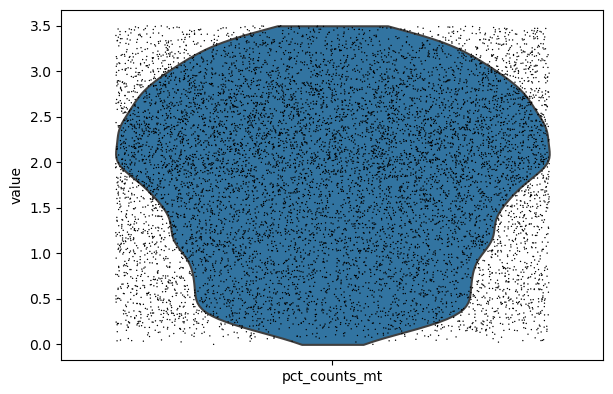

In [20]:
adata_no_nan.var_names_make_unique()
sc.pl.violin(adata_no_nan, 'pct_counts_mt', jitter=0.4)

In [21]:
# preprocess
sc.pp.normalize_total(adata_no_nan, target_sum=1e4)
sc.pp.log1p(adata_no_nan)


In [22]:

adata_filtered = adata_no_nan

In [23]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [24]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [25]:
df

,MIR1302-2HG,AL627309.1,AL627309.5,AL627309.4,AP006222.2,AL669831.2,LINC01409,FAM87B,LINC01128,LINC00115,...,MT-CYB,AC011043.1,AC011043.2,AC011841.1,AL592183.1,AC240274.1,AC004556.3,AC007325.4,AC007325.2,barcode
0,0.0,0.0,0.000000,0.0,0.0,0.0,0.742566,0.0,0.0,0.0,...,1.459537,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,GGCGTGTCCGGCTCTGGGCT
1,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,2.590622,0.000000,0.0,0.0,0.0,1.407203,0.0,0.000000,0.0,CCAGCTCTCAATGTCATGTC
2,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,3.514000,0.526644,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,ATCCCTCTGGCCGACACGAG
3,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,2.330332,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,ATCCCTCTGGCCGACACGAG
4,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,3.394570,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,CGCCCACTCGGCCTCAACGC
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9528,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,1.581552,0.000000,0.0,0.0,0.0,0.000000,0.0,0.827459,0.0,CCAGCTCTCAATGTCATGTC
9529,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,2.674954,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,ATCCCTCTGGCCGACACGAG
9530,0.0,0.0,0.000000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,3.483521,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,GCAGCTGTAACCCTGACCGG
9531,0.0,0.0,0.684949,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,...,0.684949,0.000000,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,ATCCCTCTGGCCGACACGAG


In [26]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [27]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [28]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [29]:
df.drop(columns = ["barcode"], inplace = True)

In [30]:
df.to_pickle("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/knoblich_day42_1.pkl")
